In [12]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in current folder:")
print(os.listdir())

Current working directory:
D:\Cynaris-Internship\W10D1_Time_Series_Analysis

Files in current folder:
['.ipynb_checkpoints', 'data', 'notebooks', 'outputs', 'README.md', 'src', 'Untitled.ipynb']


In [3]:
import os

print(os.getcwd())

D:\Cynaris-Internship\W10D1_Time_Series_Analysis


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    r"D:\Cynaris-Internship\W10D1_Time_Series_Analysis\data\sales.csv"
)

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [5]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
df.describe()

Rows and columns: (9800, 18)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']

Data types:
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code      float64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
dtype: object

Missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code     

,Row ID,Postal Code,Sales
count,9800.000000,9789.000000,9800.000000
mean,4900.500000,55273.322403,230.769059
std,2829.160653,32041.223413,626.651875
min,1.000000,1040.000000,0.444000
25%,2450.750000,23223.000000,17.248000
50%,4900.500000,58103.000000,54.490000
75%,7350.250000,90008.000000,210.605000
max,9800.000000,99301.000000,22638.480000


In [6]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    dayfirst=True
)

df = df.sort_values("Order Date")

print("Start date:", df["Order Date"].min())
print("End date:", df["Order Date"].max())

df.head()

Start date: 2015-01-03 00:00:00
End date: 2018-12-30 00:00:00


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
7980,7981,CA-2015-103800,2015-01-03,07/01/2015,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,Texas,77095.0,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448
741,742,CA-2015-112326,2015-01-04,08/01/2015,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540.0,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540
740,741,CA-2015-112326,2015-01-04,08/01/2015,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540.0,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736
739,740,CA-2015-112326,2015-01-04,08/01/2015,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540.0,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784
1759,1760,CA-2015-141817,2015-01-05,12/01/2015,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,Pennsylvania,19143.0,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536


In [7]:
daily_sales = (
    df.set_index("Order Date")["Sales"]
      .resample("D")
      .sum()
)

daily_sales.head(10)

Order Date
2015-01-03      16.448
2015-01-04     288.060
2015-01-05      19.536
2015-01-06    4407.100
2015-01-07      87.158
2015-01-08       0.000
2015-01-09      40.544
2015-01-10      54.830
2015-01-11       9.940
2015-01-12       0.000
Freq: D, Name: Sales, dtype: float64

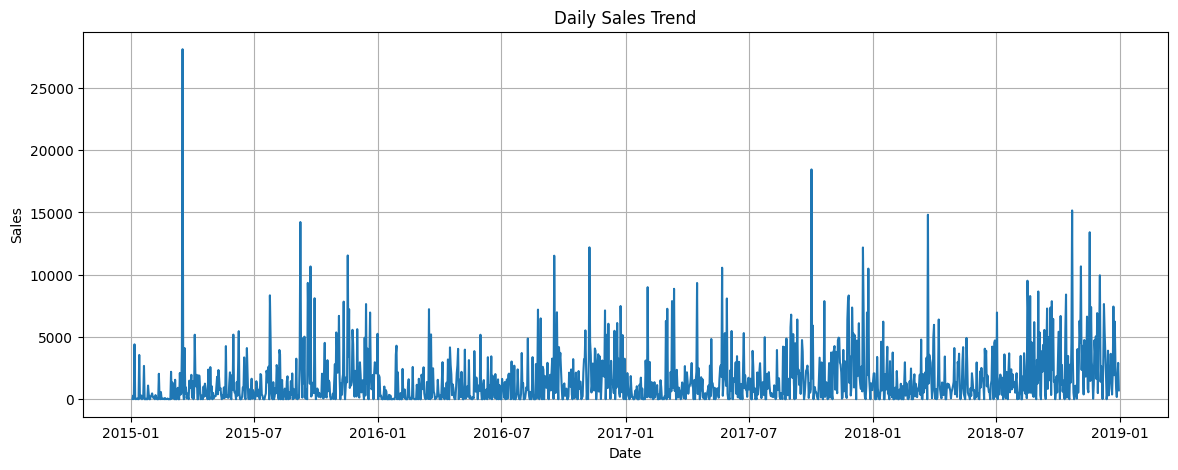

In [8]:
plt.figure(figsize=(14, 5))
plt.plot(daily_sales)

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid()
plt.show()

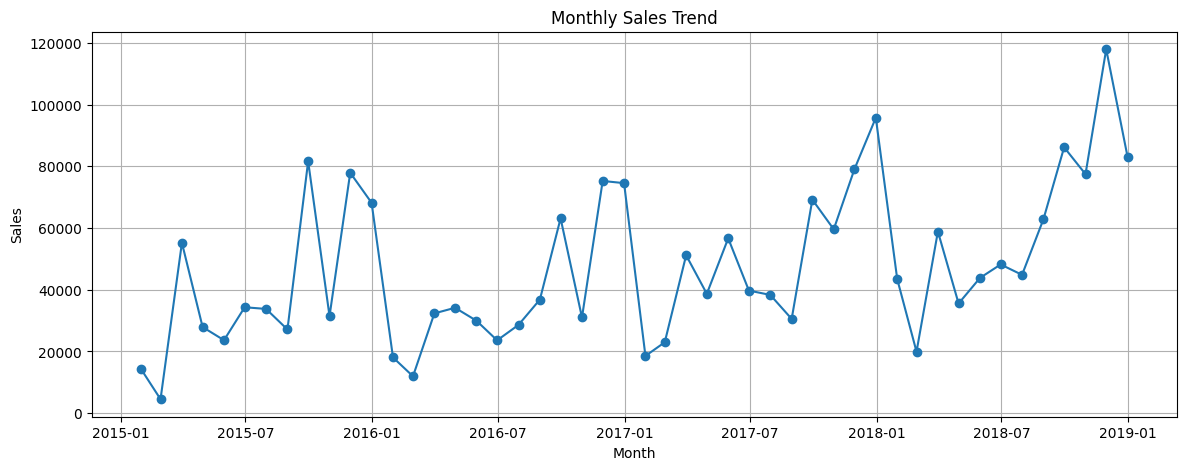

In [9]:
monthly_sales = daily_sales.resample("ME").sum()

plt.figure(figsize=(14, 5))
plt.plot(monthly_sales, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.grid()
plt.show()

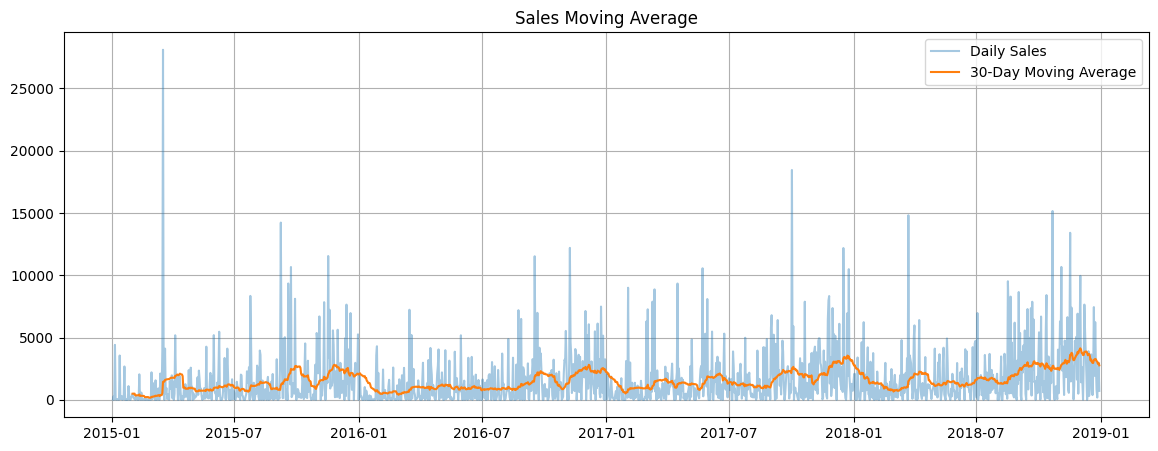

In [10]:
moving_average = daily_sales.rolling(window=30).mean()

plt.figure(figsize=(14, 5))
plt.plot(daily_sales, alpha=0.4, label="Daily Sales")
plt.plot(moving_average, label="30-Day Moving Average")

plt.title("Sales Moving Average")
plt.legend()
plt.grid()
plt.show()

In [1]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv(
    r"D:\Cynaris-Internship\W10D1_Time_Series_Analysis\data\sales.csv"
)

# Convert date
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    dayfirst=True
)

# Sort dates
df = df.sort_values("Order Date")

# Aggregate daily sales
daily_sales = (
    df.set_index("Order Date")["Sales"]
    .resample("D")
    .sum()
)

# Aggregate monthly sales
monthly_sales = daily_sales.resample("ME").sum()

print("Daily records:", len(daily_sales))
print("Monthly records:", len(monthly_sales))
print("Data preparation successful!")

Daily records: 1458
Monthly records: 48
Data preparation successful!


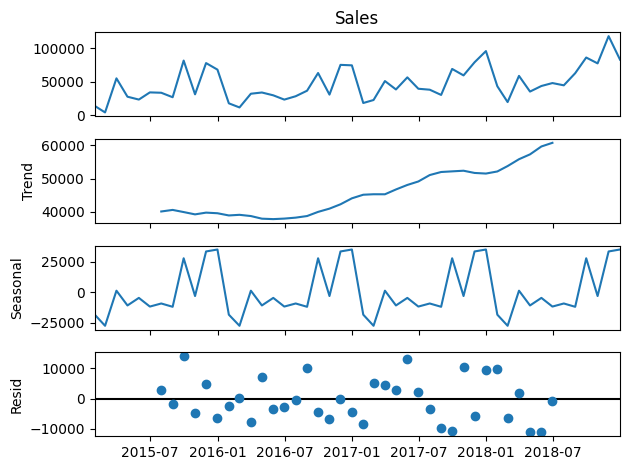

In [4]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    monthly_sales,
    model="additive",
    period=12
)

decomposition.plot()
plt.show()

In [6]:
from statsmodels.tsa.arima.model import ARIMA
import numpy as np

# Split data
train = monthly_sales.iloc[:-6]
test = monthly_sales.iloc[-6:]

# Train ARIMA model
model = ARIMA(train, order=(1, 1, 1))
model_fit = model.fit()

# Forecast
forecast = model_fit.forecast(steps=6)

# Calculate errors manually
errors = test.values - forecast.values

mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors ** 2))

print("ARIMA MODEL RESULTS")
print("-------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

ARIMA MODEL RESULTS
-------------------
MAE: 31769.88
RMSE: 38018.13


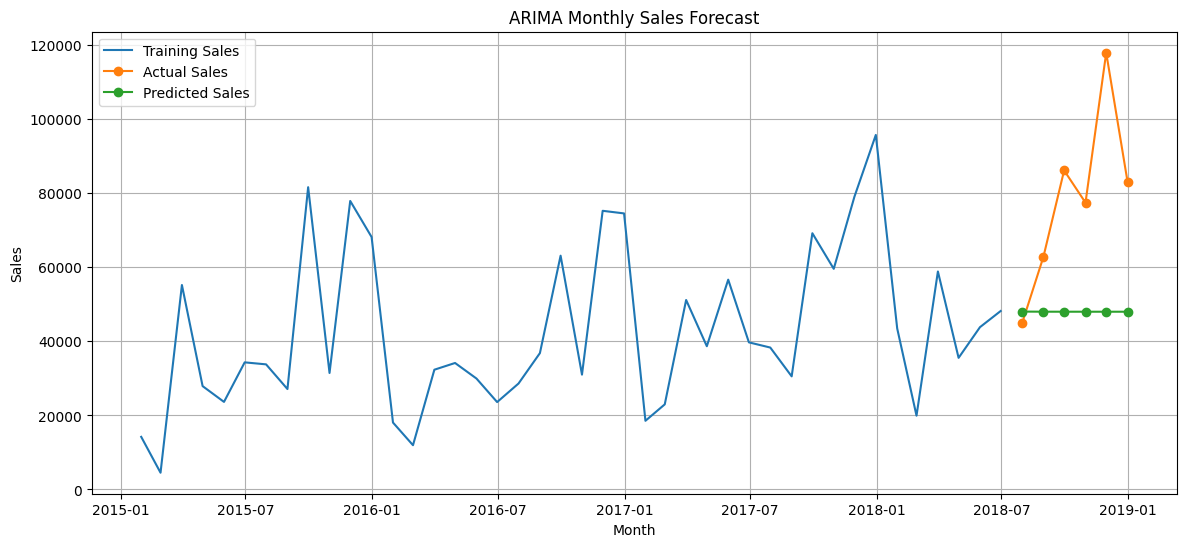

In [7]:
plt.figure(figsize=(14, 6))

plt.plot(train.index, train, label="Training Sales")
plt.plot(test.index, test, marker="o", label="Actual Sales")
plt.plot(test.index, forecast, marker="o", label="Predicted Sales")

plt.title("ARIMA Monthly Sales Forecast")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid()
plt.show()
